# Experiment 7: all-fish transition/static raster

This notebook follows the shared all-fish workflow used for experiments 1 and 5. It loads the experiment 7 cohort, validates its stimulus map, and generates z-score rasters, mean traces, left/right activity diagnostics, motion-period counts, and lifetime-sparseness figures.

Fish IDs, data location, blocks, and stimulus order come from `archive/notebooks/calcium/Exp7_trans_stat_several.ipynb`. The 25-second post-onset window follows its later configuration cell (the earlier cell used 32 seconds). The 8-second motion onset agrees with the experiment 7 stimulus configuration; the 6-second response extension follows the shared workflow.

Edit `USER_SETTINGS` and the figure controls beside each plot. With `data_base=None`, the shared loader discovers this computer's OneDrive Lab folders automatically. For a manual override, set `data_base` to the parent of the university OneDrive folder, such as `Path.home()` here or `Path(r'D:\Alejandro\Data')` on the other computer. All five fish must have the processed traces, significant-raster caches, and kept-neuron indices required by the shared loader. Reports are disabled until a run has been reviewed.


## 1. Setup and imports

In [1]:
# Cell 01 - Setup
from pathlib import Path
import sys
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src').is_dir())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.plotting_common as plot_common
import src.several_fish_figures as several_figures
import src.several_fish_loading as several_loading
import src.several_fish_reporting as several_reporting
for module in (plot_common, several_figures, several_loading, several_reporting):
    importlib.reload(module)


## Publication layout and export

Figures are drawn at their **final print size**, using DejaVu Sans: 8 pt axis labels and
titles, 7 pt ticks/legends, and 9 pt figure headings. DejaVu Sans ships with Matplotlib
and supports the scientific symbols here. Change `PUBLICATION_STYLE` below for a
journal-specific font. Re-run the plotting cells after changing the style.

An A4 sheet is 210 × 297 mm. With 15 mm margins the working area is 180 × 267 mm.
Small panels use about 85 mm width; dense grids use 180 mm width and 100–135 mm
height, leaving room for several panels, captions, and panel letters. Each 2 × 2
grid already contains four panels. Keep these dimensions when placing the figures;
shrinking a figure also shrinks its text. Sizes remain beside each plotting call.

Set `EXPORT_PUBLICATION_FIGURES=True` and run the export cell after reviewing the
plots. It writes editable PDF/SVG plus 600 dpi PNG into the configured folder.
The canvas is not cropped, so exported widths and heights match the millimetre
settings. These are individual figure blocks to assemble into a manuscript layout.


In [2]:
# Physical sizes are millimetres; font sizes are points at the final print size.
MM = 1 / 25.4
PUBLICATION_STYLE = {
    'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.labelsize': 8, 'axes.titlesize': 8, 'figure.titlesize': 9,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'legend.title_fontsize': 7, 'axes.linewidth': 0.6,
    'lines.linewidth': 1.0, 'lines.markersize': 3,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'figure.dpi': 150, 'savefig.dpi': 600, 'savefig.bbox': None,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'mathtext.fontset': 'dejavusans', 'figure.facecolor': 'white',
}
plt.rcParams.update(PUBLICATION_STYLE)
EXPORT_PUBLICATION_FIGURES = False  # Enable after reviewing the figures.
PUBLICATION_FORMATS = ('pdf', 'svg', 'png')
PUBLICATION_DPI = 600
PUBLICATION_DIR = repo_root / 'notebooks/calcium/exp_07_trans_stat/publication_figures/01'


## 2. Experiment 7 settings

In [3]:
# Experiment 7 cohort and plotting settings from the archived several-fish notebook.
USER_SETTINGS = {
    'experiment_name': 'Exp_7_trans_stat',
    'analysis_label': 'Exp 7 transition/static',
    'data_base': None,  # Auto-discover OneDrive; use a parent Path for a manual override.
    'fish_ids': ['L742_f03', 'L742_f05', 'L742_f06', 'L742_f09', 'L742_f10'],
    'selected_blocks': ['B1', 'B2', 'B3', 'B4'],
    'verbose_loading': False,
    'timing': {
        'fps_2p': 2.0, 't_pre_s': 5.0, 't_post_s': 25.0,
        'motion_onset_s': 8.0, 'tau_s': 6.0,
    },
    # Preserve the archive's right-side group followed by its left-side group.
    'stim_order': [14, 9, 11, 13, 4, 6, 2, 7, 8, 10, 12, 3, 5, 1],
    'combine_mode': 'mean',  # 'mean' or 'concat'.
    'trace_type': 'zscore',
    'raster_sort_mode': 'left_right_index',  # 'corravg' matches the archived raster.
    'left_control': 7,    # LeBcontrol
    'right_control': 14,  # RiBcontrol
}

# Check the archive's ID/name contract against the loaded experiment, not another experiment.
EXPECTED_STIMULUS_MAP = {
    'DF300Le': 1, 'DF300Ri': 2, 'F300Le': 3, 'F300Ri': 4,
    'F600Le': 5, 'F600Ri': 6, 'LeBcontrol': 7,
    'R300Le': 8, 'R300Ri': 9, 'R600Le': 10, 'R600Ri': 11,
    'RF600Le': 12, 'RF600Ri': 13, 'RiBcontrol': 14,
}

REPORT_SETTINGS = {
    'save_report': False,
    'run_label': 'exp7_trans_stat_all_fish_raster',
    'report_format': 'html',
    'export_notebook': True,
    'fallback_to_html': True,
    'comments': 'Enable only after reviewing the Exp 7 figures.',
}


## 3. Load and validate fish data

In [4]:
# Load every configured fish and validate the experiment 7 stimulus mapping.
raster_inputs = several_loading.load_and_preflight_fish_raster_inputs(USER_SETTINGS)
globals().update(raster_inputs)
for fish_id, fish_data in all_fish_data.items():
    if any(fish_data['stimuli_id_map'].get(name) != stimulus_id
           for name, stimulus_id in EXPECTED_STIMULUS_MAP.items()):
        raise ValueError(f"Unexpected Exp 7 stimulus map for {fish_id}: {fish_data['stimuli_id_map']}")
stimuli_colors, stimuli_linestyles = plot_common.build_stimulus_style_maps(stimuli_names=stimuli_names)
print('Data root:', main_path)
print('Analysis root:', analysis_path)
print('Detected Exp 7 stimulus map:', stimuli_id_map)


Data root: C:\Users\suribear\OneDrive - Université de Lausanne\Lab\Data\2p
Analysis root: C:\Users\suribear\OneDrive - Université de Lausanne\Lab\Analysis
Detected Exp 7 stimulus map: {'DF300Le': 1, 'DF300Ri': 2, 'F300Le': 3, 'F300Ri': 4, 'F600Le': 5, 'F600Ri': 6, 'LeBcontrol': 7, 'R300Le': 8, 'R300Ri': 9, 'R600Le': 10, 'R600Ri': 11, 'RF600Le': 12, 'RF600Ri': 13, 'RiBcontrol': 14}


## 4. All-fish z-score raster

This panel uses **89 × 65 mm** and **6 pt Arial** at final print size, so it fits
beside another panel on an A4 page. The local style applies to this raster only.
The four-column legend, mean trace, and colorbar are included inside that size.
Keep the exported dimensions when placing the panel in the manuscript.

[Nature's figure guide](https://research-figure-guide.nature.com/figures/building-and-exporting-figure-panels/)
specifies 89 mm single-column width and 5–7 pt text. Six points is the practical
small-text choice here; the figure-specific controls below remain editable.


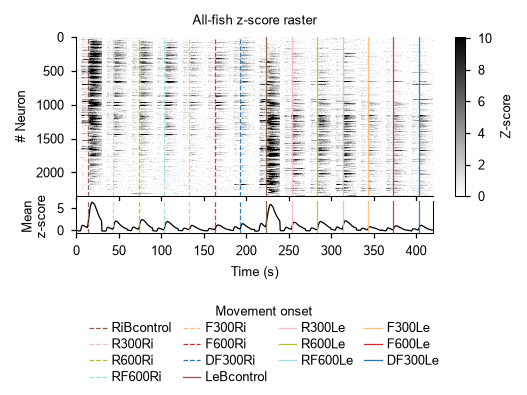

In [5]:
# Final-size single-column panel; controls apply to this figure only.
RASTER_WIDTH_MM, RASTER_HEIGHT_MM = 89, 65
RASTER_FONT_PT = 6
RASTER_LEGEND_COLUMNS = 4
RASTER_STYLE = {
    **PUBLICATION_STYLE,
    'font.family': 'Arial', 'font.size': RASTER_FONT_PT,
    'axes.labelsize': RASTER_FONT_PT, 'axes.titlesize': RASTER_FONT_PT,
    'xtick.labelsize': RASTER_FONT_PT, 'ytick.labelsize': RASTER_FONT_PT,
    'legend.fontsize': RASTER_FONT_PT, 'legend.title_fontsize': RASTER_FONT_PT,
    'axes.linewidth': 0.5, 'lines.linewidth': 0.6,
}
FIGSIZE = (RASTER_WIDTH_MM * MM, RASTER_HEIGHT_MM * MM)
with plt.rc_context(RASTER_STYLE):
    raster_result = several_figures.build_all_fish_raster_figure(
        all_fish_data, fish_ids, stim_order, reference_fish, timing, settings,
        stimuli_colors, stimuli_linestyles, figsize=FIGSIZE,
    )
    raster_figure, raster_axis = raster_result['figure'], raster_result['axes']
    raster_axis.set_title('All-fish z-score raster')
    for axis in raster_figure.axes:
        plt.setp(axis.lines, linewidth=0.6)
    handles, labels = raster_axis.get_legend_handles_labels()
    raster_figure.legends[0].remove()
    raster_figure.legend(
        handles, labels, title='Movement onset', loc='lower center',
        ncol=RASTER_LEGEND_COLUMNS, frameon=False, handlelength=1.4,
        columnspacing=0.9, handletextpad=0.4, labelspacing=0.3,
    )
    raster_figure.subplots_adjust(left=0.13, right=0.87, bottom=0.40, top=0.91,
                                  hspace=0.10, wspace=0.14)
    plt.show()
flat_matrix_all_fish = raster_result['flat_matrix_all_fish']


## 5. Mean z-score traces

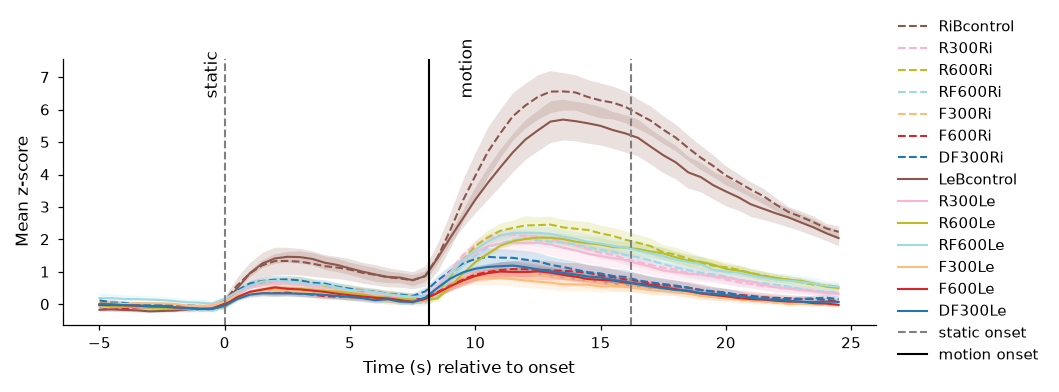

In [6]:
# Mean z-score traces in the same experiment 7 stimulus order.
FIGSIZE = (180 * MM, 65 * MM)
mean_trace_result = several_figures.build_plot_all_fish_mean_zscore_traces(
    all_fish_data, fish_ids, stim_order, reference_fish, timing,
    stimuli_colors, stimuli_linestyles, figsize=FIGSIZE,
)
plt.show()


## 6. Left/right activity diagnostics

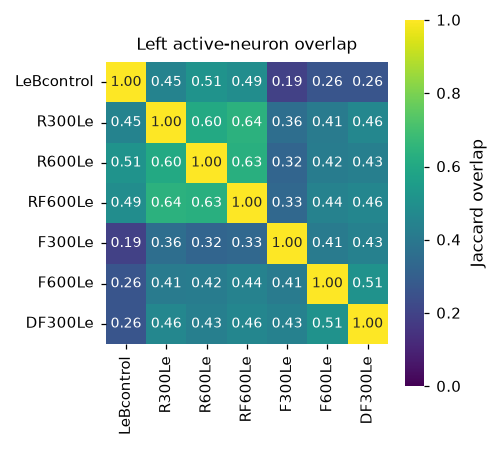

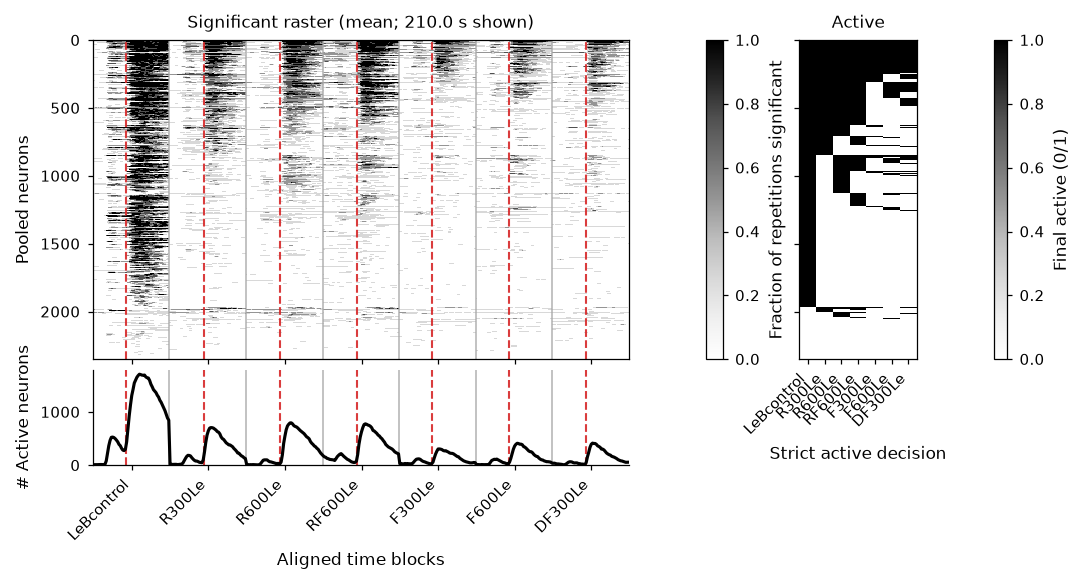

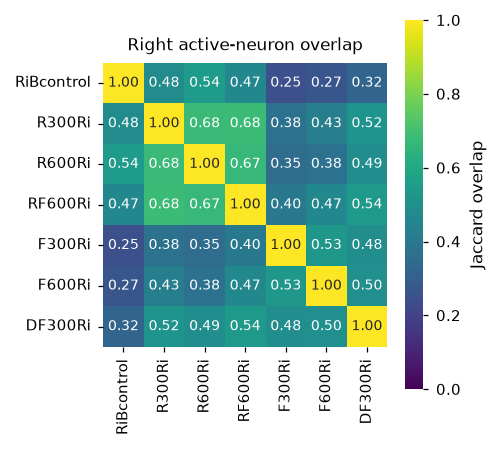

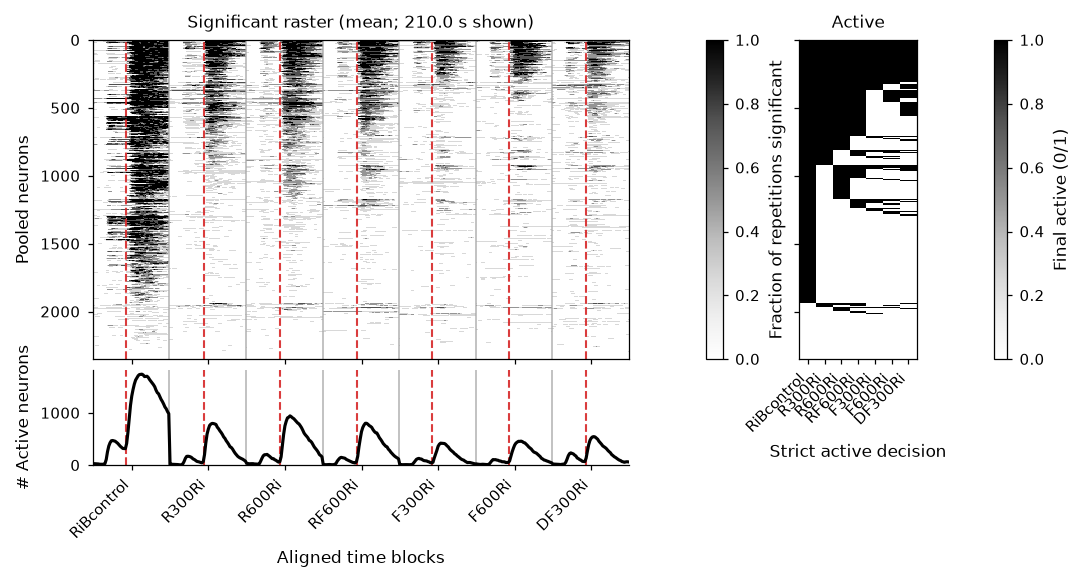

In [7]:
# Matched left/right groups from the archive's stimulus map.
OVERLAP_FIGSIZE = (85 * MM, 80 * MM)
RASTER_FIGSIZE = (180 * MM, 100 * MM)
OVERLAP_STIMULI = {
    'left': [7, 8, 10, 12, 3, 5, 1],
    'right': [14, 9, 11, 13, 4, 6, 2],
}
overlap_results = several_figures.plot_left_right_active_overlap_diagnostics(
    all_fish_data, fish_ids, reference_fish, timing, OVERLAP_STIMULI,
    motion_onset_s=timing['motion_onset_s'], tau_s=timing['tau_s'],
    show_overlap=True, show_significant_raster=True,
    overlap_figsize=OVERLAP_FIGSIZE, raster_figsize=RASTER_FIGSIZE,
)


## 7. Motion-period active-neuron counts

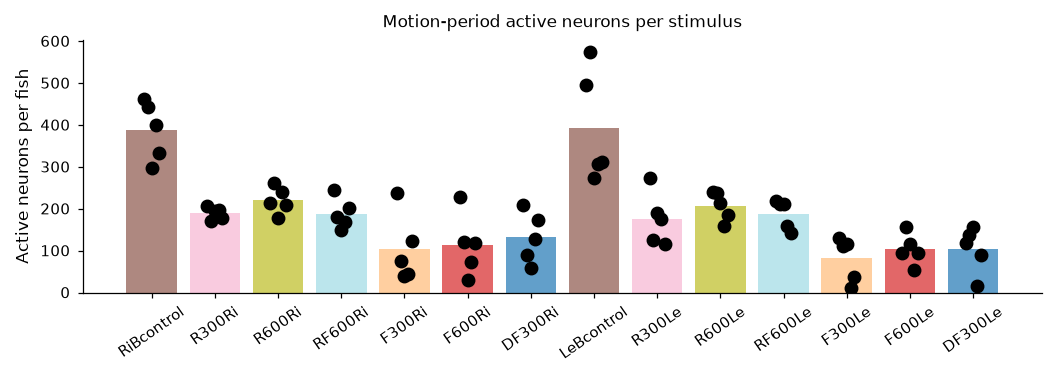

In [8]:
# Motion-period active-neuron counts, preserving the configured stimulus order.
FIGSIZE = (180 * MM, 65 * MM)
motion_active_result = several_figures.plot_motion_active_neuron_counts(
    all_fish_data, fish_ids, reference_fish, timing, stim_order, stimuli_colors,
    figsize=FIGSIZE, motion_onset_s=timing['motion_onset_s'], tau_s=timing['tau_s'],
)
active_neuron_counts = motion_active_result['counts']


## 8. Lifetime sparseness and high-sparseness raster

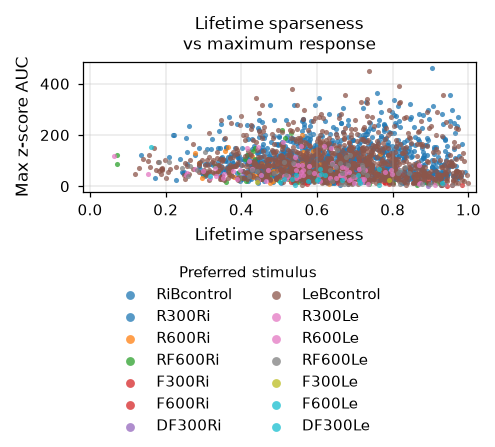

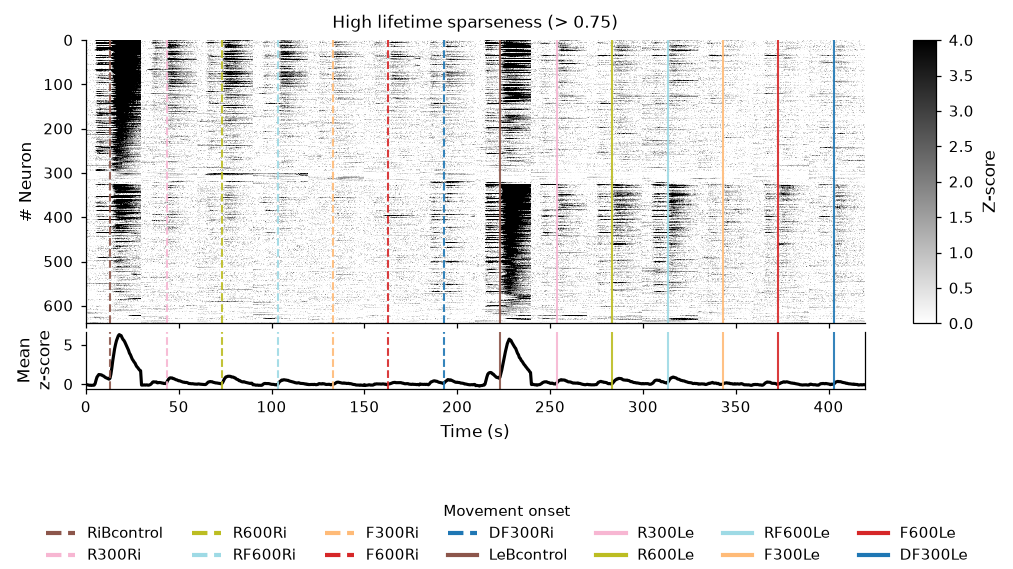

In [9]:
# Lifetime sparseness across the selected experiment 7 stimuli.
SPARSENESS_FIGSIZE = (85 * MM, 75 * MM)
RASTER_FIGSIZE = (180 * MM, 100 * MM)
SPARSENESS_STIMULI = stim_order  # Edit to select a subset of IDs or names.
HIGH_LIFETIME_SPARSENESS = 0.75
HIGH_SPARSENESS_COMBINE_MODE = 'mean'
sparseness_result = several_figures.plot_lifetime_sparseness_analysis(
    all_fish_data, fish_ids, reference_fish, timing, SPARSENESS_STIMULI,
    HIGH_LIFETIME_SPARSENESS, stimuli_colors, stimuli_linestyles,
    combine_mode=HIGH_SPARSENESS_COMBINE_MODE,
    sparseness_figsize=SPARSENESS_FIGSIZE, raster_figsize=RASTER_FIGSIZE,
    analysis_label=settings['analysis_label'],
)


## 9. Optional analysis report

In [10]:
# Cell 09 - Optional reviewed-run report
# Save this notebook before enabling REPORT_SETTINGS['save_report'] so the HTML includes current outputs.
notebook_path = repo_root / 'notebooks' / 'calcium' / 'exp_07_trans_stat' / '01_all_fish_raster.ipynb'
report_summary = pd.DataFrame([
    {
        'fish_id': fish_id,
        'kept_neurons': len(fish_data['kept_neuron_indices']),
        'detected_stimuli': len(fish_data['stimuli_ids']),
    }
    for fish_id, fish_data in all_fish_data.items()
])
report_result = several_reporting.save_analysis_report_run(
    settings=settings,
    report_settings=REPORT_SETTINGS,
    analysis_path=analysis_path,
    tables={'run_summary': report_summary},
    notebook_path=notebook_path,
    report_name='01_all_fish_raster_report',
    extra_metadata={
        'stim_order': stim_order,
        'combine_mode': settings['combine_mode'],
        'trace_type': settings['trace_type'],
        'raster_sort_mode': settings['raster_sort_mode'],
        'all_fish_matrix_shape': flat_matrix_all_fish.shape,
    },
)
report_result


Report saving is off. Set REPORT_SETTINGS['save_report'] = True to save this run.


## Export reviewed publication figures

Run after the plotting cells; the style cell controls whether files are written.


In [11]:
publication_figures = {
    'all_fish_raster': raster_result['figure'],
    'mean_zscore_traces': mean_trace_result['figure'],
    'motion_active_counts': motion_active_result['figure'],
    'lifetime_sparseness': sparseness_result['sparseness_figure'],
    'high_sparseness_raster': sparseness_result['high_sparseness_figure'],
}
for side, result in overlap_results.items():
    for key in ('overlap_figure', 'diagnostic_figure'):
        if key in result:
            publication_figures[f'{side}_{key}'] = result[key]
if EXPORT_PUBLICATION_FIGURES:
    for name, figure in publication_figures.items():
        if figure is not None:
            plot_common.save_publication_figure(
                figure, PUBLICATION_DIR / name,
                formats=PUBLICATION_FORMATS, dpi=PUBLICATION_DPI,
            )
    print('Publication figures:', PUBLICATION_DIR)
